In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    make_scorer
)

from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 404

RANDOM_STATE = 42
print('Libraries imported successfully ✅')

Libraries imported successfully ✅


In [2]:
import pandas as pd

file_path = r"C:\Users\teluk\OneDrive\Documents\Downloads\organic_farming_suitability_1000_source_calibrated.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

Dataset loaded successfully.
Total rows: 1000
Total columns: 24


In [3]:
display(df.head())

,Sample_ID,State,Soil_Type,Crop,pH,Organic_Carbon_pct,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Available_S_mg_kg,...,Available_B_mg_kg,EC_dS_m,Annual_Rainfall_mm,Mean_Temperature_C,Soil_Moisture_pct,Previous_Fertilizer_Usage,Previous_Pesticide_Usage,Years_Chemical_Input,Suitability_Score,Organic_Farming_Suitability
0,OF-0001,Haryana,Sandy,Tomato,6.13,0.411,80.0,65.2,266.9,15.71,...,0.29,0.191,954.2,26.5,17.9,Mixed,Low,0,39.1,Not Suitable
1,OF-0002,Andhra Pradesh,Loamy,Sugarcane,7.58,0.826,187.8,29.4,131.5,13.64,...,0.65,0.652,841.9,30.7,33.6,Chemical,Moderate,8,53.0,Not Suitable
2,OF-0003,Karnataka,Loamy,Pulses,6.00,0.684,353.4,3.0,351.5,20.35,...,0.48,0.317,562.3,23.0,30.6,Chemical,Moderate,12,45.2,Not Suitable
3,OF-0004,Madhya Pradesh,Red,Pulses,6.69,0.706,200.3,39.0,61.7,10.96,...,2.51,0.323,741.1,26.8,33.5,Chemical,Moderate,8,44.7,Not Suitable
4,OF-0005,Madhya Pradesh,Red,Sugarcane,6.46,1.564,181.3,11.7,411.4,14.66,...,0.65,0.512,870.0,25.0,24.3,Chemical,High,2,52.6,Not Suitable


In [4]:
display(df.tail())

,Sample_ID,State,Soil_Type,Crop,pH,Organic_Carbon_pct,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Available_S_mg_kg,...,Available_B_mg_kg,EC_dS_m,Annual_Rainfall_mm,Mean_Temperature_C,Soil_Moisture_pct,Previous_Fertilizer_Usage,Previous_Pesticide_Usage,Years_Chemical_Input,Suitability_Score,Organic_Farming_Suitability
995,OF-0996,Karnataka,Laterite,Soybean,6.02,0.469,367.3,3.0,472.3,6.01,...,0.48,0.671,1260.1,26.7,25.6,Mixed,Moderate,0,43.7,Not Suitable
996,OF-0997,Rajasthan,Loamy,Rice,7.47,1.900,181.2,40.5,490.6,27.51,...,0.49,1.059,504.7,32.9,41.9,Chemical,Moderate,4,81.6,Suitable
997,OF-0998,Maharashtra,Laterite,Potato,6.68,0.631,252.6,3.0,373.7,15.84,...,0.41,0.450,789.1,25.7,32.2,Organic,High,1,46.4,Not Suitable
998,OF-0999,Assam,Black,Sugarcane,5.01,0.541,86.9,35.7,341.8,18.22,...,0.78,0.239,704.7,24.5,16.4,Chemical,Moderate,7,20.3,Not Suitable
999,OF-1000,Rajasthan,Laterite,Mustard,5.30,0.658,366.7,24.3,223.3,13.23,...,0.40,0.500,1314.0,25.4,37.9,Mixed,Moderate,3,22.6,Not Suitable


In [5]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
for column in df.columns:
    print(column)

Dataset shape: (1000, 24)

Column names:
Sample_ID
State
Soil_Type
Crop
pH
Organic_Carbon_pct
Available_N_kg_ha
Available_P_kg_ha
Available_K_kg_ha
Available_S_mg_kg
Available_Zn_mg_kg
Available_Fe_mg_kg
Available_Mn_mg_kg
Available_Cu_mg_kg
Available_B_mg_kg
EC_dS_m
Annual_Rainfall_mm
Mean_Temperature_C
Soil_Moisture_pct
Previous_Fertilizer_Usage
Previous_Pesticide_Usage
Years_Chemical_Input
Suitability_Score
Organic_Farming_Suitability


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Sample_ID                    1000 non-null   str    
 1   State                        1000 non-null   str    
 2   Soil_Type                    1000 non-null   str    
 3   Crop                         1000 non-null   str    
 4   pH                           1000 non-null   float64
 5   Organic_Carbon_pct           1000 non-null   float64
 6   Available_N_kg_ha            1000 non-null   float64
 7   Available_P_kg_ha            1000 non-null   float64
 8   Available_K_kg_ha            1000 non-null   float64
 9   Available_S_mg_kg            1000 non-null   float64
 10  Available_Zn_mg_kg           1000 non-null   float64
 11  Available_Fe_mg_kg           1000 non-null   float64
 12  Available_Mn_mg_kg           1000 non-null   float64
 13  Available_Cu_mg_kg           1

In [7]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
pH,1000.0,6.915940,0.754045,4.800,6.40000,6.9250,7.42000,9.190
Organic_Carbon_pct,1000.0,0.724501,0.346696,0.189,0.48100,0.6535,0.87725,2.500
Available_N_kg_ha,1000.0,259.016700,91.347824,80.000,194.07500,257.3000,315.82500,588.100
Available_P_kg_ha,1000.0,29.549400,16.859065,3.000,16.47500,29.1000,40.82500,86.300
Available_K_kg_ha,1000.0,254.252700,126.799430,40.000,165.70000,242.3500,345.92500,653.200
Available_S_mg_kg,1000.0,15.801290,6.615834,3.000,11.28250,15.5400,20.25750,39.060
Available_Zn_mg_kg,1000.0,0.785150,0.366406,0.150,0.53000,0.7100,0.96000,4.000
Available_Fe_mg_kg,1000.0,20.480830,12.802683,2.990,11.91500,17.3350,25.31250,80.000
Available_Mn_mg_kg,1000.0,9.191230,5.361124,1.440,5.49000,7.7650,11.62500,40.000
Available_Cu_mg_kg,1000.0,0.774470,0.385222,0.170,0.51750,0.6950,0.93000,4.000


In [8]:
numeric_columns_all = df.select_dtypes(include=["number"]).columns.tolist()
categorical_columns_all = df.select_dtypes(include=["object"]).columns.tolist()

print("Numerical columns:")
display(numeric_columns_all)

print("Categorical columns:")
display(categorical_columns_all)

Numerical columns:


C:\Users\teluk\AppData\Local\Temp\ipykernel_13424\12538809.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns_all = df.select_dtypes(include=["object"]).columns.tolist()


['pH',
 'Organic_Carbon_pct',
 'Available_N_kg_ha',
 'Available_P_kg_ha',
 'Available_K_kg_ha',
 'Available_S_mg_kg',
 'Available_Zn_mg_kg',
 'Available_Fe_mg_kg',
 'Available_Mn_mg_kg',
 'Available_Cu_mg_kg',
 'Available_B_mg_kg',
 'EC_dS_m',
 'Annual_Rainfall_mm',
 'Mean_Temperature_C',
 'Soil_Moisture_pct',
 'Years_Chemical_Input',
 'Suitability_Score']

Categorical columns:


['Sample_ID',
 'State',
 'Soil_Type',
 'Crop',
 'Previous_Fertilizer_Usage',
 'Previous_Pesticide_Usage',
 'Organic_Farming_Suitability']

In [9]:
df.columns = df.columns.str.strip()
display(df.columns.tolist())

['Sample_ID',
 'State',
 'Soil_Type',
 'Crop',
 'pH',
 'Organic_Carbon_pct',
 'Available_N_kg_ha',
 'Available_P_kg_ha',
 'Available_K_kg_ha',
 'Available_S_mg_kg',
 'Available_Zn_mg_kg',
 'Available_Fe_mg_kg',
 'Available_Mn_mg_kg',
 'Available_Cu_mg_kg',
 'Available_B_mg_kg',
 'EC_dS_m',
 'Annual_Rainfall_mm',
 'Mean_Temperature_C',
 'Soil_Moisture_pct',
 'Previous_Fertilizer_Usage',
 'Previous_Pesticide_Usage',
 'Years_Chemical_Input',
 'Suitability_Score',
 'Organic_Farming_Suitability']

In [10]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

display(missing_summary)

,Missing_Count,Missing_Percentage
Sample_ID,0,0.0
State,0,0.0
Soil_Type,0,0.0
Crop,0,0.0
pH,0,0.0
Organic_Carbon_pct,0,0.0
Available_N_kg_ha,0,0.0
Available_P_kg_ha,0,0.0
Available_K_kg_ha,0,0.0
Available_S_mg_kg,0,0.0


In [11]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Sample_ID values:", df["Sample_ID"].duplicated().sum())

Duplicate rows: 0
Duplicate Sample_ID values: 0


In [12]:
df = df.drop_duplicates().copy()

print("Dataset shape after duplicate removal:", df.shape)

Dataset shape after duplicate removal: (1000, 24)


In [13]:
target_column = "Organic_Farming_Suitability"

print("Target classes:")
display(df[target_column].value_counts(dropna=False))

print("Target class percentages:")
display((df[target_column].value_counts(normalize=True) * 100).round(2))

Target classes:


Organic_Farming_Suitability
Not Suitable    577
Suitable        423
Name: count, dtype: int64

Target class percentages:


Organic_Farming_Suitability
Not Suitable    57.7
Suitable        42.3
Name: proportion, dtype: float64

In [14]:
numeric_data = df.select_dtypes(include=["number"])

print("Total infinite values:", np.isinf(numeric_data).sum().sum())

df = df.replace([np.inf, -np.inf], np.nan)

print("Dataset shape:", df.shape)

Total infinite values: 0
Dataset shape: (1000, 24)


In [15]:
cleaning_summary = pd.DataFrame({
    "Data_Type": df.dtypes.astype(str),
    "Missing_Values": df.isnull().sum(),
    "Unique_Values": df.nunique()
})

display(cleaning_summary)
print("Final dataset size:", df.shape)

,Data_Type,Missing_Values,Unique_Values
Sample_ID,str,0,1000
State,str,0,15
Soil_Type,str,0,7
Crop,str,0,12
pH,float64,0,313
Organic_Carbon_pct,float64,0,639
Available_N_kg_ha,float64,0,844
Available_P_kg_ha,float64,0,456
Available_K_kg_ha,float64,0,856
Available_S_mg_kg,float64,0,783


Final dataset size: (1000, 24)


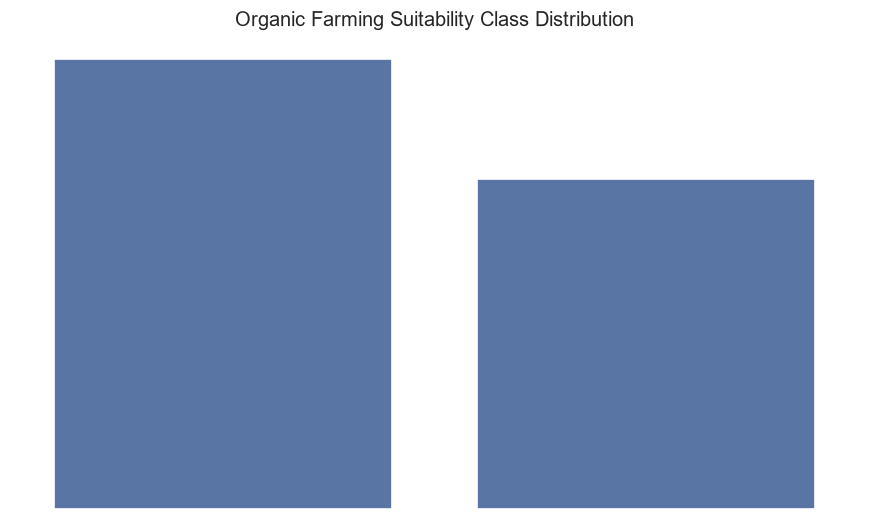

In [16]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x=target_column, order=df[target_column].value_counts().index)
plt.title("Organic Farming Suitability Class Distribution")
plt.xlabel("Suitability Class")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.axis(False)
plt.show()

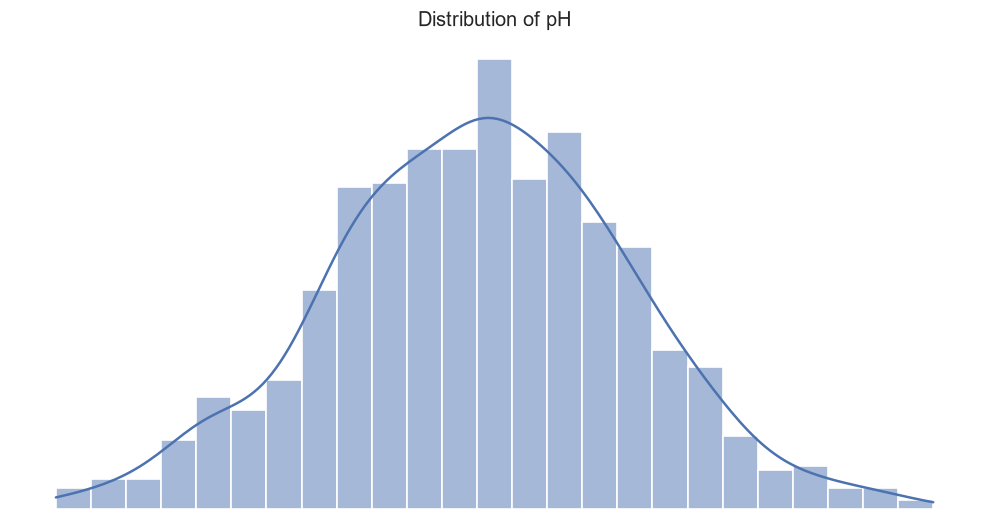

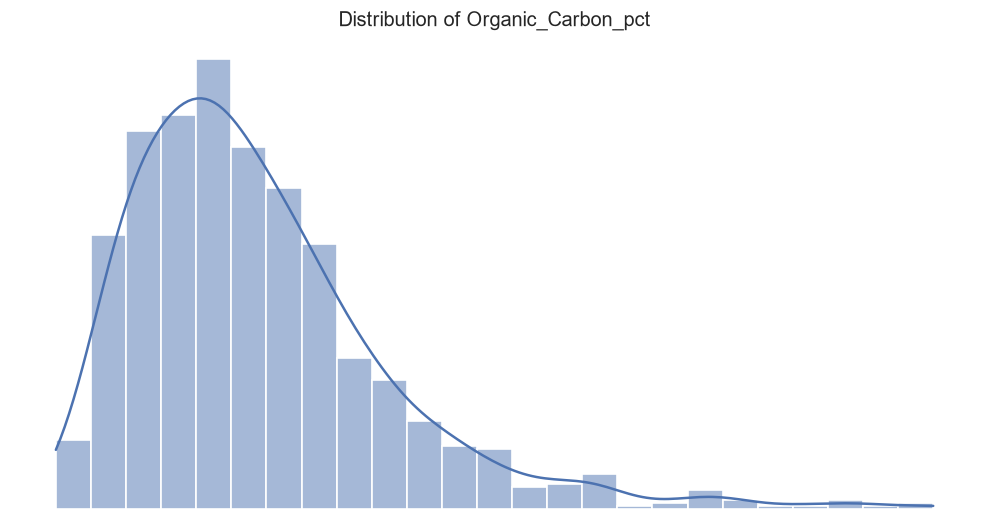

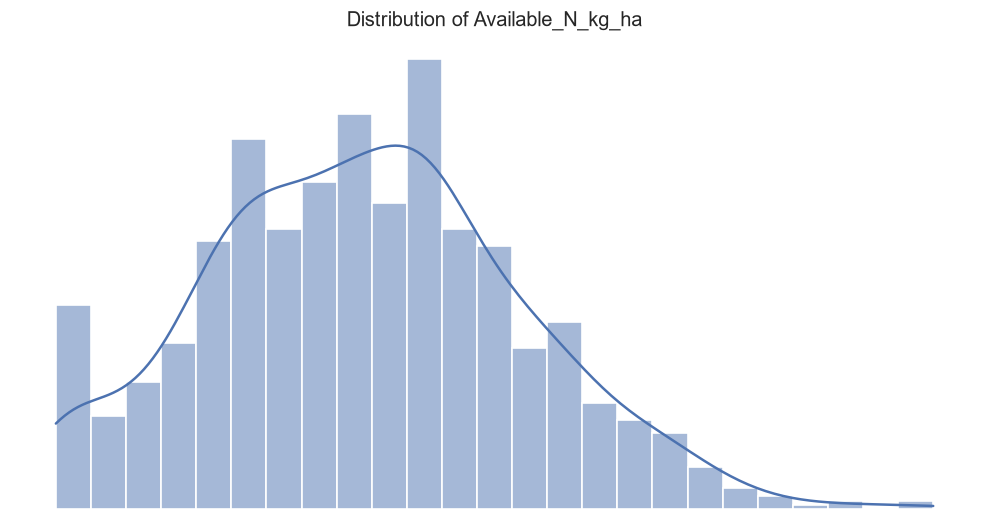

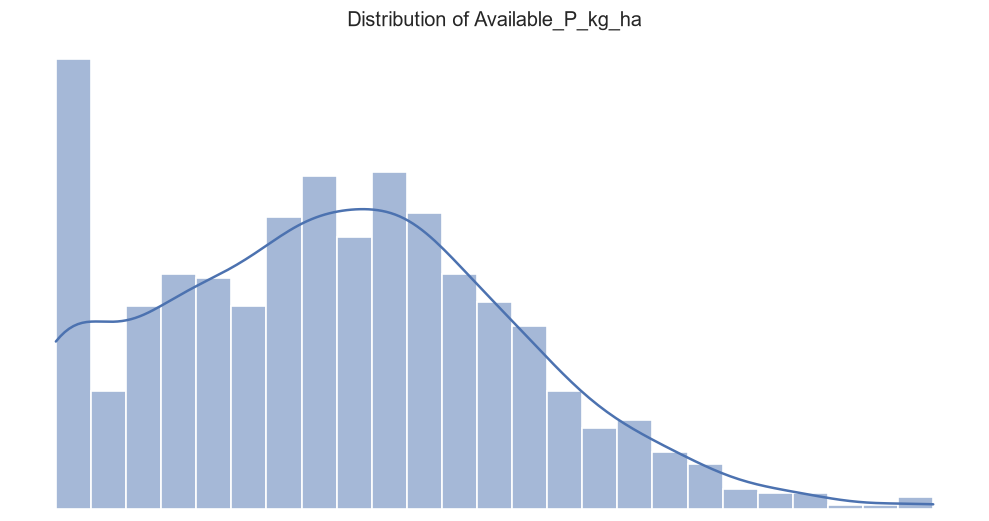

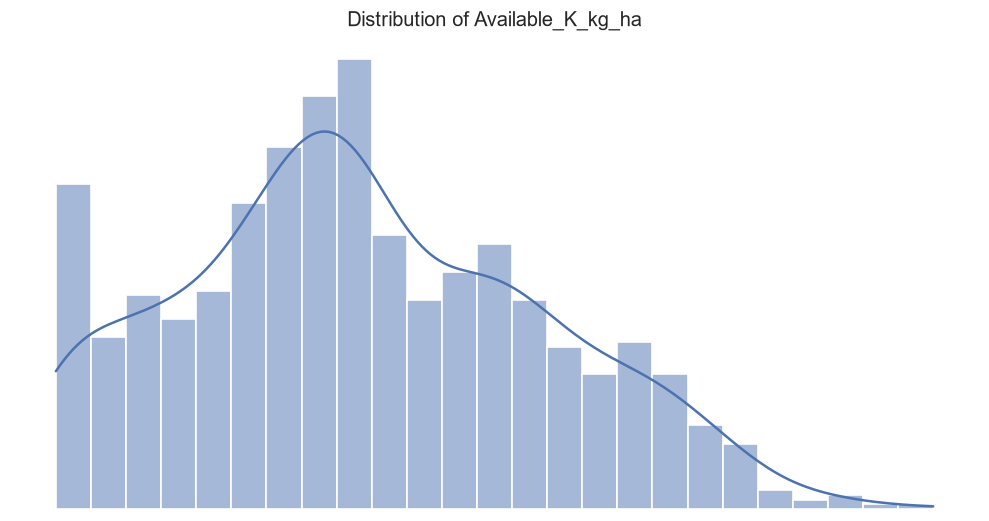

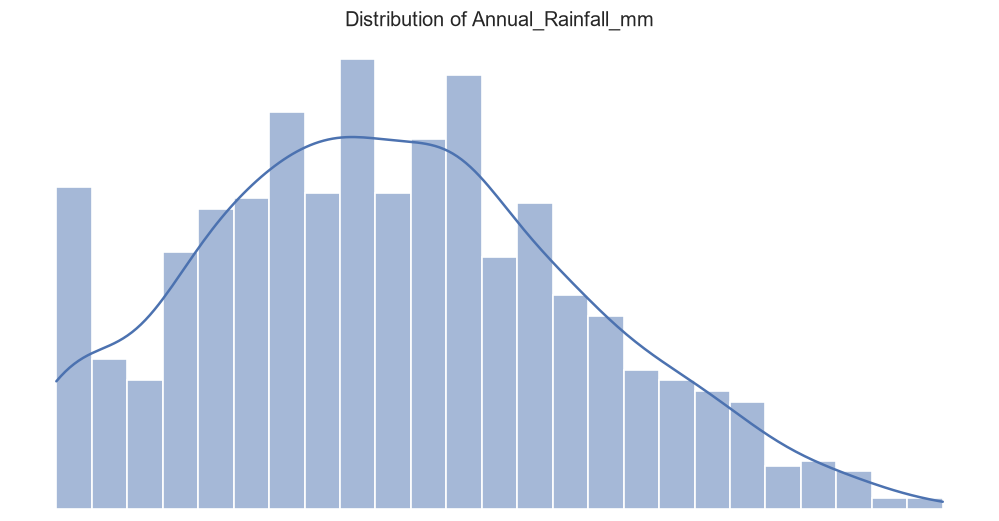

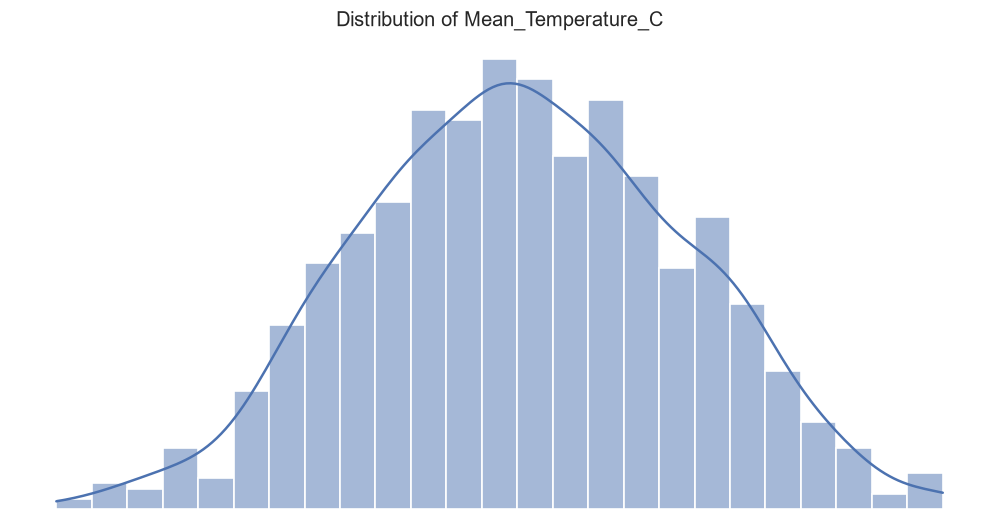

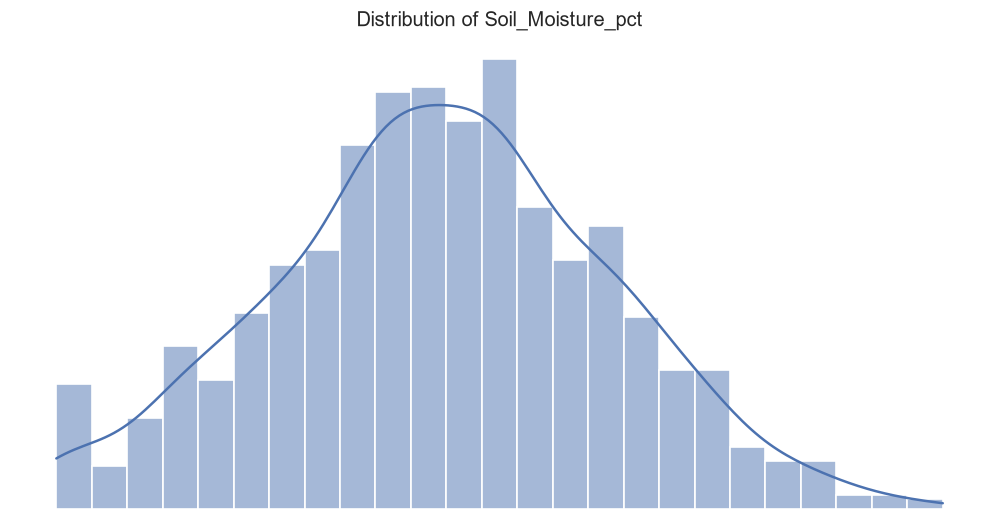

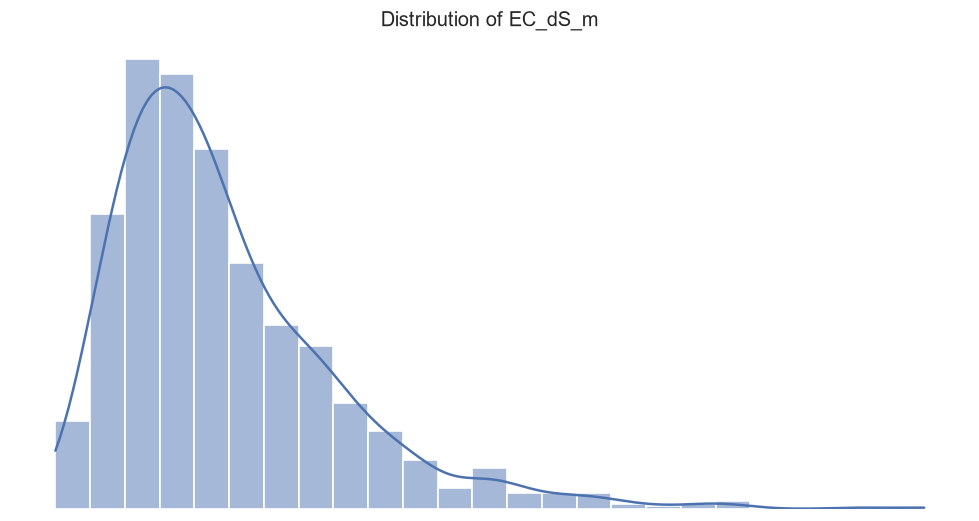

In [17]:
eda_numeric_columns = [
    "pH",
    "Organic_Carbon_pct",
    "Available_N_kg_ha",
    "Available_P_kg_ha",
    "Available_K_kg_ha",
    "Annual_Rainfall_mm",
    "Mean_Temperature_C",
    "Soil_Moisture_pct",
    "EC_dS_m"
]

for column in eda_numeric_columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(data=df, x=column, kde=True, bins=25)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.axis(False)
    plt.show()

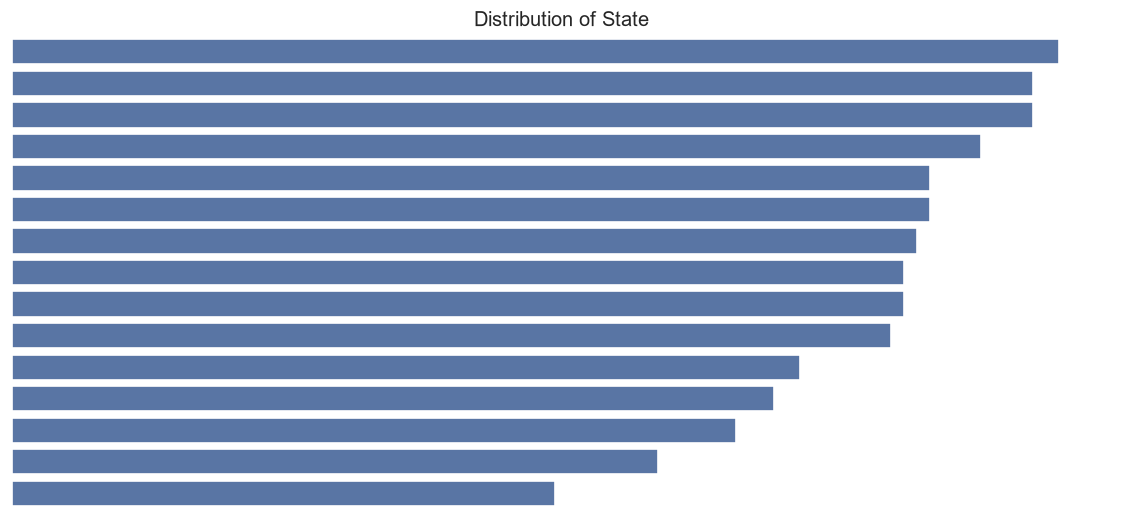

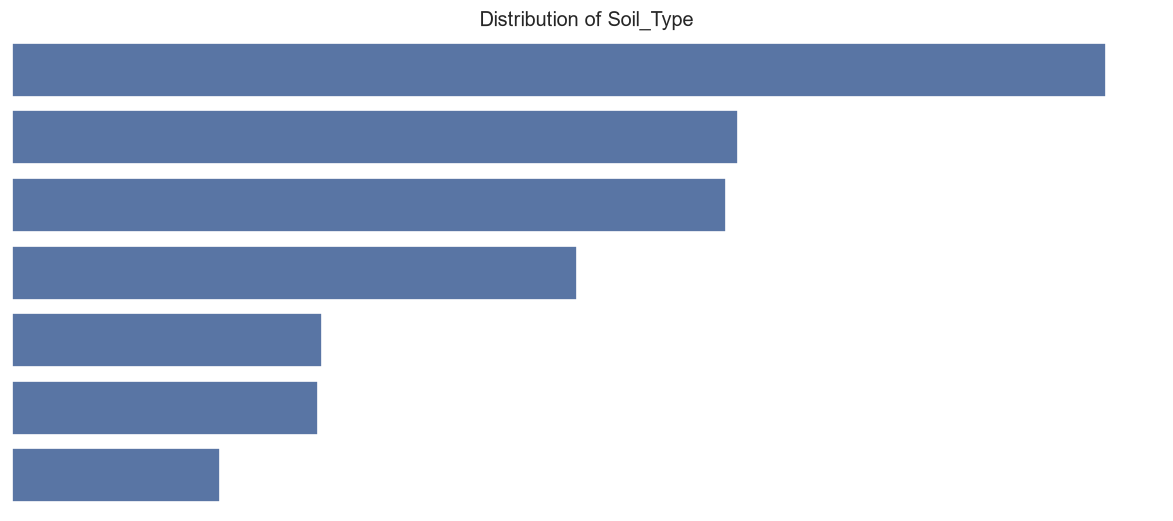

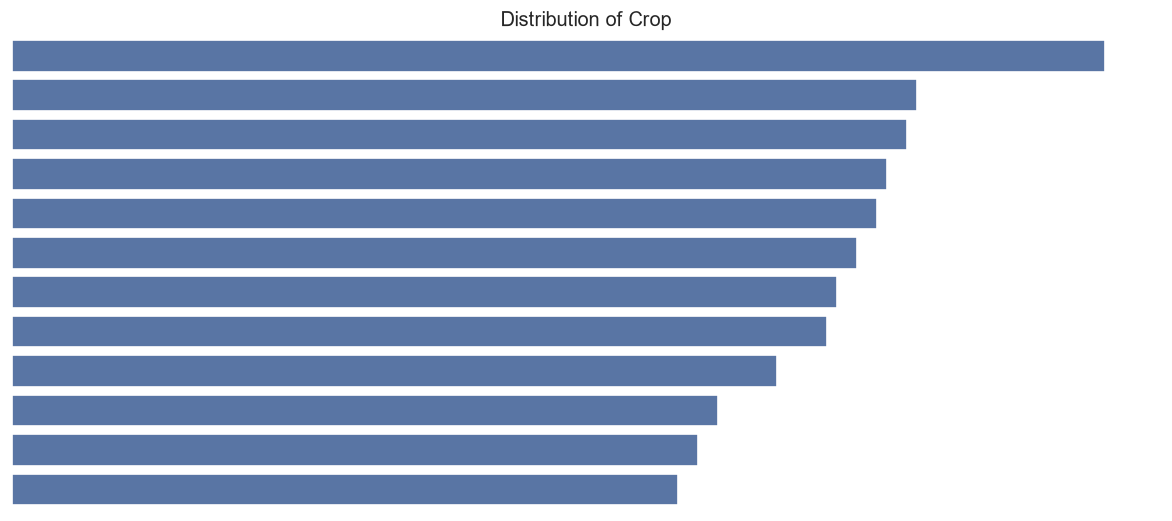

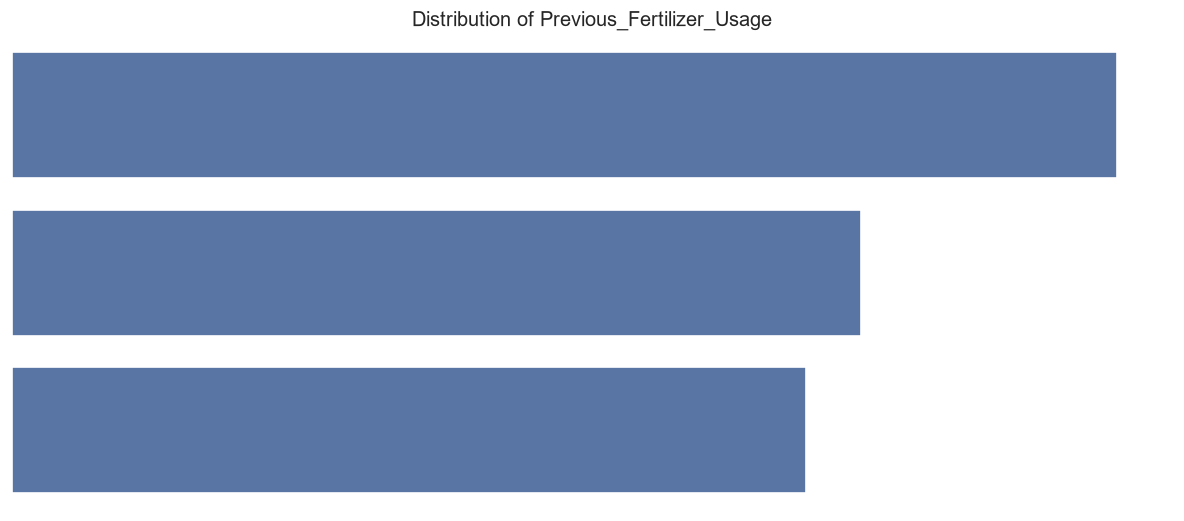

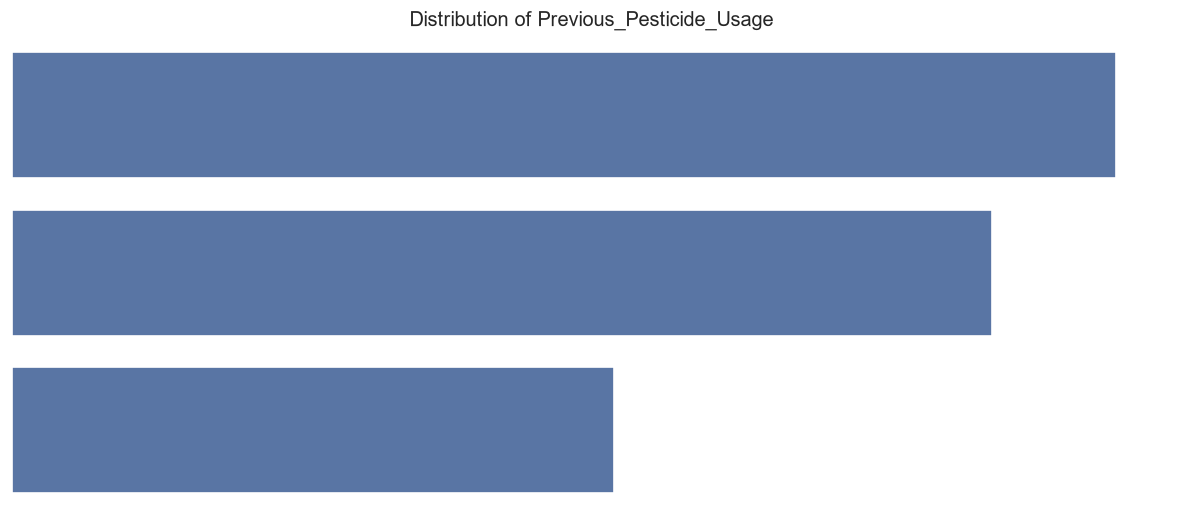

In [18]:
eda_categorical_columns = [
    "State",
    "Soil_Type",
    "Crop",
    "Previous_Fertilizer_Usage",
    "Previous_Pesticide_Usage"
]

for column in eda_categorical_columns:
    plt.figure(figsize=(11, 5))
    order = df[column].value_counts().index
    sns.countplot(data=df, y=column, order=order)
    plt.title(f"Distribution of {column}")
    plt.xlabel("Number of Records")
    plt.ylabel(column)
    plt.tight_layout()
    plt.axis(False)
    plt.show()

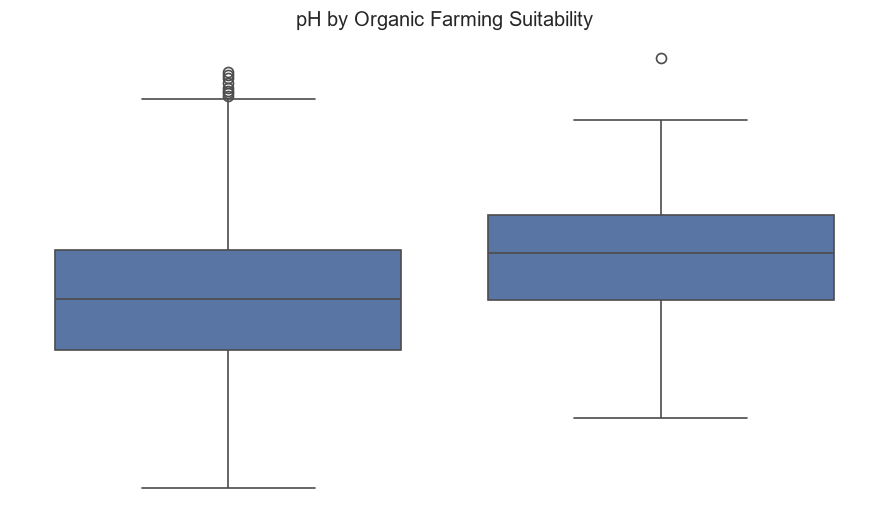

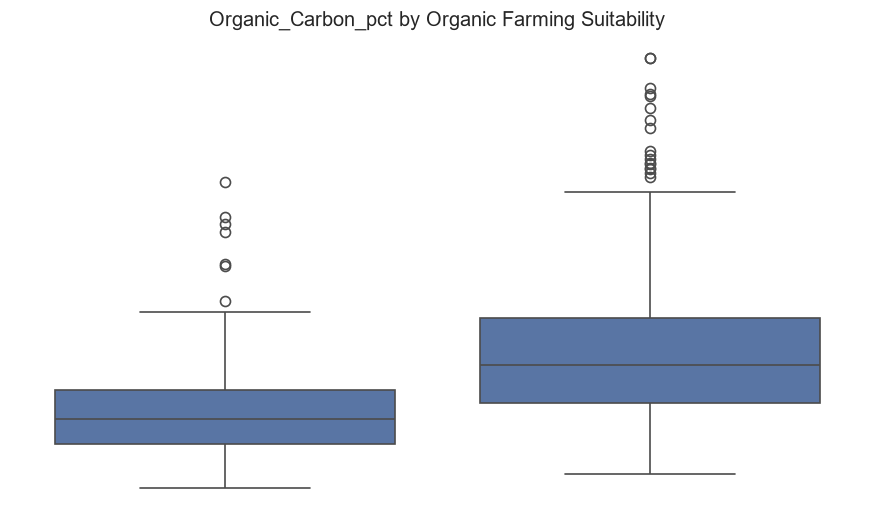

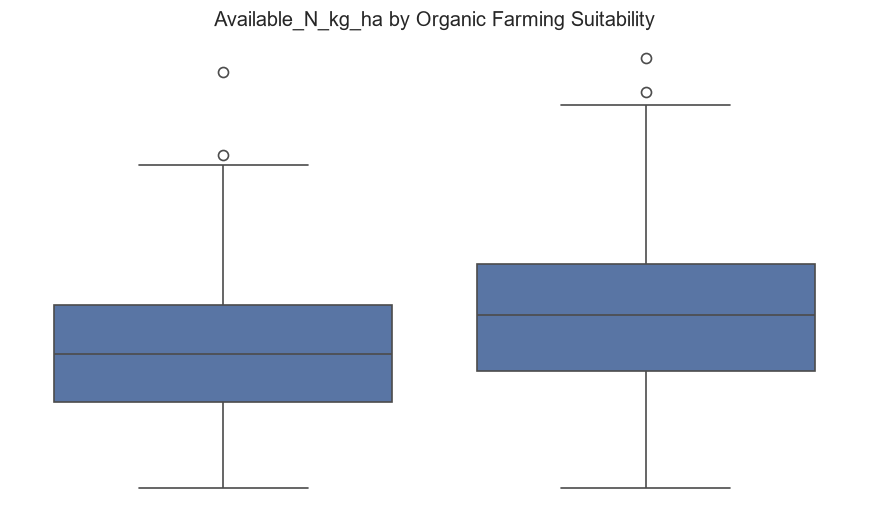

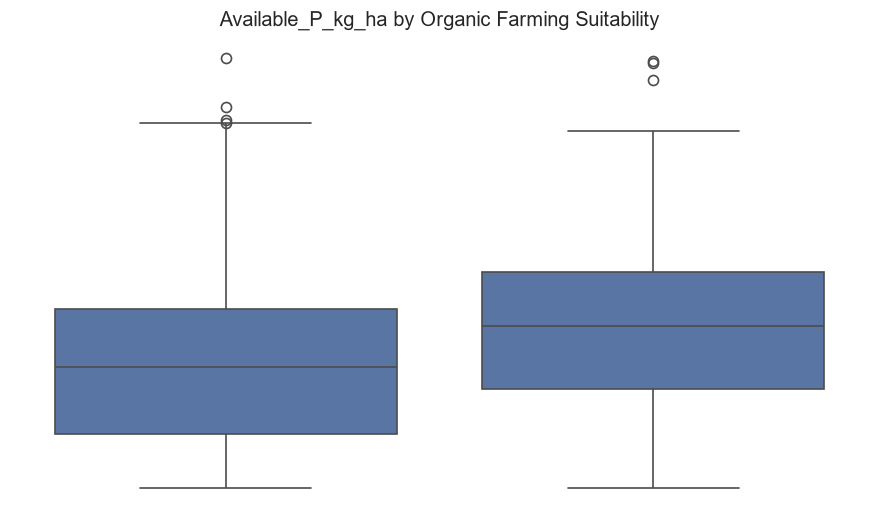

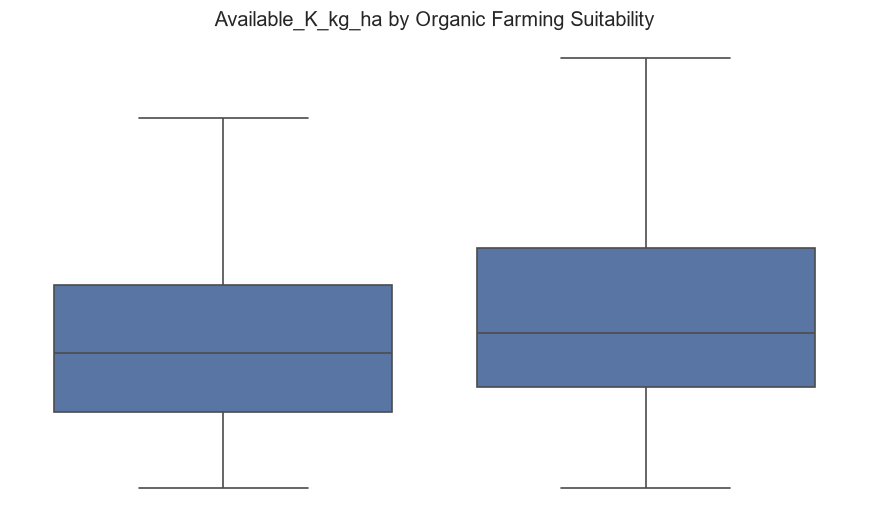

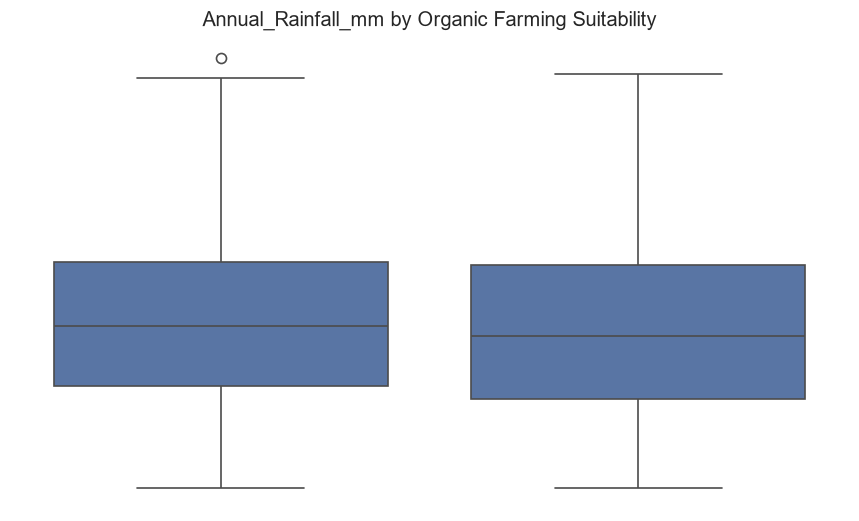

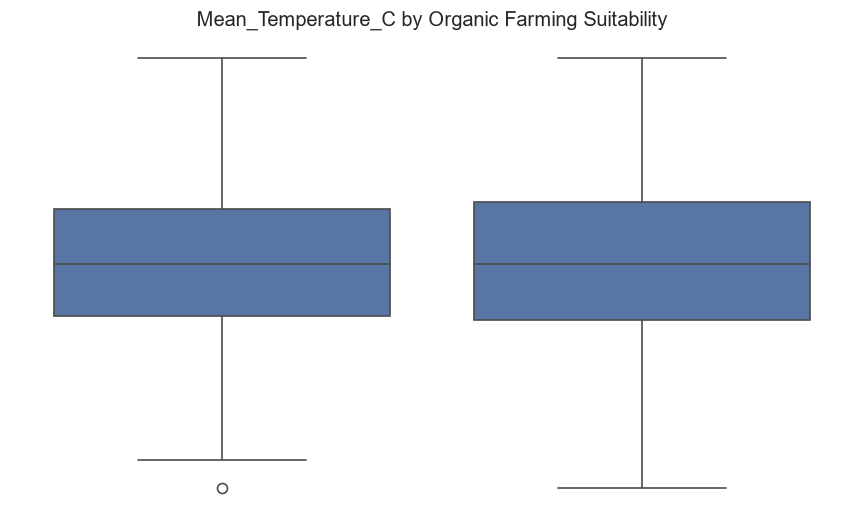

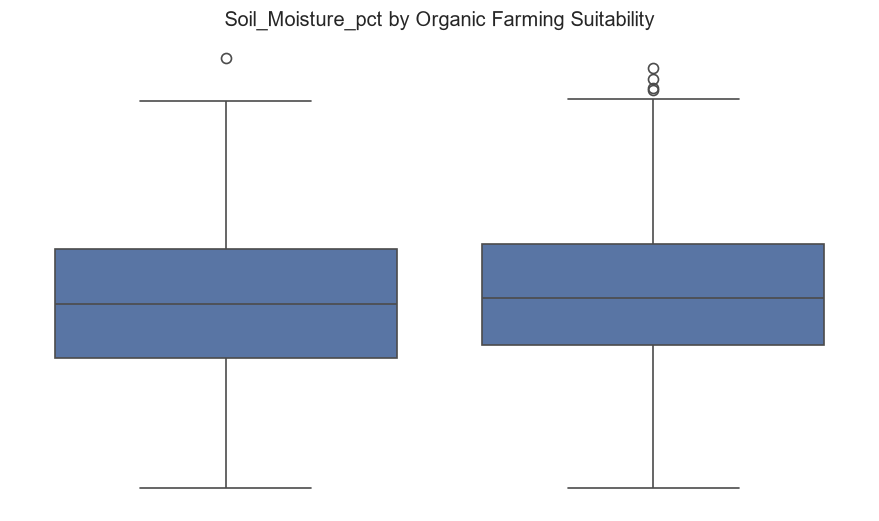

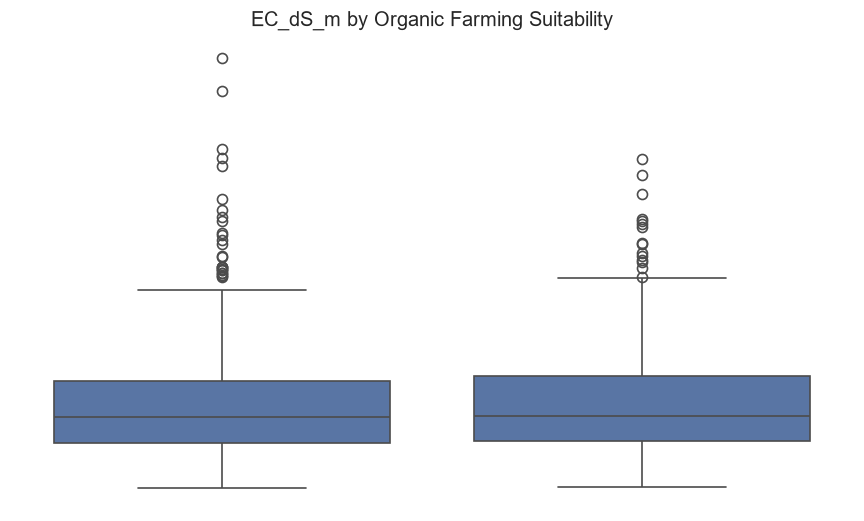

In [19]:
for column in eda_numeric_columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x=target_column, y=column)
    plt.title(f"{column} by Organic Farming Suitability")
    plt.xlabel("Suitability Class")
    plt.ylabel(column)
    plt.tight_layout()
    plt.axis(False)
    plt.show()

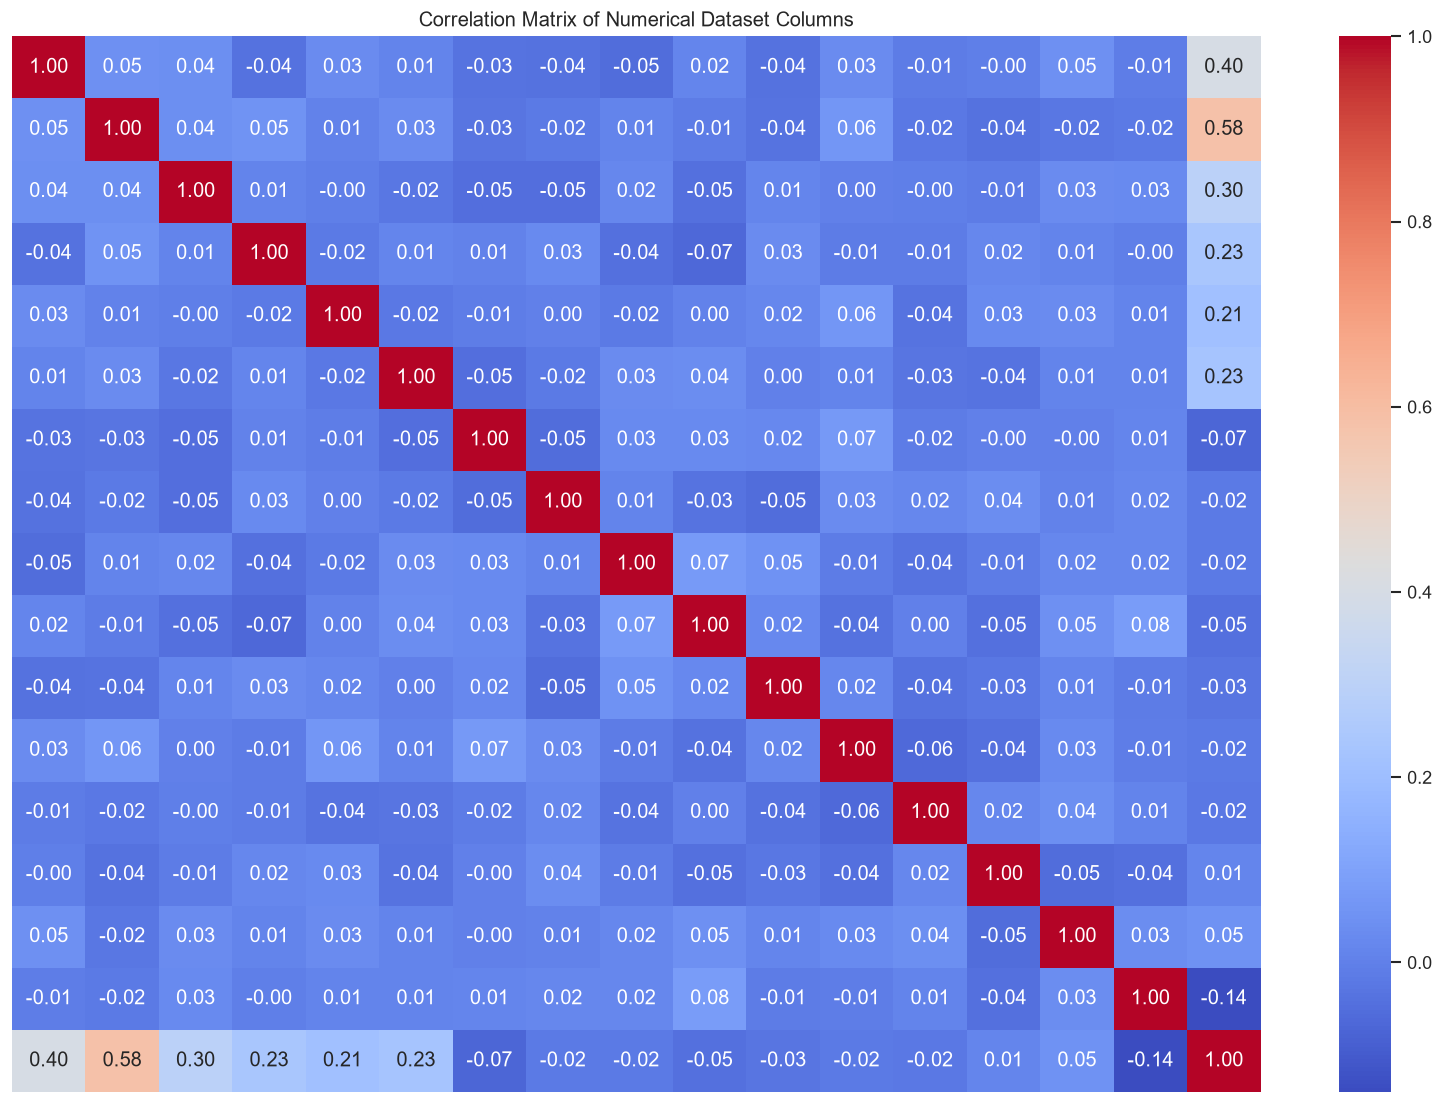

In [20]:
correlation_matrix = df.select_dtypes(include=["number"]).corr()

plt.figure(figsize=(15, 11))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0
)
plt.title("Correlation Matrix of Numerical Dataset Columns")
plt.tight_layout()
plt.axis(False)
plt.show()

In [21]:
target_column = "Organic_Farming_Suitability"

excluded_columns = [
    "Sample_ID",
    "Suitability_Score",
    target_column
]

X = df.drop(columns=excluded_columns)
y = df[target_column].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.value_counts())

Feature matrix shape: (1000, 21)
Target shape: (1000,)


,State,Soil_Type,Crop,pH,Organic_Carbon_pct,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Available_S_mg_kg,Available_Zn_mg_kg,...,Available_Mn_mg_kg,Available_Cu_mg_kg,Available_B_mg_kg,EC_dS_m,Annual_Rainfall_mm,Mean_Temperature_C,Soil_Moisture_pct,Previous_Fertilizer_Usage,Previous_Pesticide_Usage,Years_Chemical_Input
0,Haryana,Sandy,Tomato,6.13,0.411,80.0,65.2,266.9,15.71,0.33,...,20.76,1.43,0.29,0.191,954.2,26.5,17.9,Mixed,Low,0
1,Andhra Pradesh,Loamy,Sugarcane,7.58,0.826,187.8,29.4,131.5,13.64,0.66,...,11.35,0.71,0.65,0.652,841.9,30.7,33.6,Chemical,Moderate,8
2,Karnataka,Loamy,Pulses,6.00,0.684,353.4,3.0,351.5,20.35,0.81,...,30.98,0.72,0.48,0.317,562.3,23.0,30.6,Chemical,Moderate,12
3,Madhya Pradesh,Red,Pulses,6.69,0.706,200.3,39.0,61.7,10.96,0.95,...,5.20,0.73,2.51,0.323,741.1,26.8,33.5,Chemical,Moderate,8
4,Madhya Pradesh,Red,Sugarcane,6.46,1.564,181.3,11.7,411.4,14.66,0.64,...,3.03,0.72,0.65,0.512,870.0,25.0,24.3,Chemical,High,2


Organic_Farming_Suitability
Not Suitable    577
Suitable        423
Name: count, dtype: int64

In [22]:
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical features:")
display(numeric_features)

print("Categorical features:")
display(categorical_features)

Numerical features:


C:\Users\teluk\AppData\Local\Temp\ipykernel_13424\2718357951.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()


['pH',
 'Organic_Carbon_pct',
 'Available_N_kg_ha',
 'Available_P_kg_ha',
 'Available_K_kg_ha',
 'Available_S_mg_kg',
 'Available_Zn_mg_kg',
 'Available_Fe_mg_kg',
 'Available_Mn_mg_kg',
 'Available_Cu_mg_kg',
 'Available_B_mg_kg',
 'EC_dS_m',
 'Annual_Rainfall_mm',
 'Mean_Temperature_C',
 'Soil_Moisture_pct',
 'Years_Chemical_Input']

Categorical features:


['State',
 'Soil_Type',
 'Crop',
 'Previous_Fertilizer_Usage',
 'Previous_Pesticide_Usage']

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 800
Testing records: 200


In [24]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [25]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_split=5,
        random_state=RANDOM_STATE
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        random_state=RANDOM_STATE,
        class_weight="balanced"
    )
}

print("Models prepared:")
display(list(models.keys()))

Models prepared:


['Logistic Regression',
 'Decision Tree',
 'K-Nearest Neighbors',
 'Random Forest']

In [26]:
trained_models = {}

for model_name, model in models.items():
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    model_pipeline.fit(X_train, y_train)
    trained_models[model_name] = model_pipeline

print("All four classification models have been trained.")

All four classification models have been trained.


In [27]:
model_predictions = {}

for model_name, model in trained_models.items():
    model_predictions[model_name] = model.predict(X_test)

print("Predictions generated for all models.")

Predictions generated for all models.


In [28]:
evaluation_results = []

for model_name, model in trained_models.items():
    y_pred = model_predictions[model_name]
    y_probability = model.predict_proba(X_test)[:, list(model.classes_).index("Suitable")]

    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label="Suitable", zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label="Suitable", zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, pos_label="Suitable", zero_division=0),
        "ROC-AUC": roc_auc_score((y_test == "Suitable").astype(int), y_probability)
    })

results_df = pd.DataFrame(evaluation_results)
results_df = results_df.sort_values(
    by=["F1 Score", "ROC-AUC", "Accuracy"],
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.805,0.7875,0.7412,0.7636,0.8891
1,Random Forest,0.785,0.7442,0.7529,0.7485,0.8836
2,K-Nearest Neighbors,0.765,0.7714,0.6353,0.6968,0.8144
3,Decision Tree,0.740,0.6941,0.6941,0.6941,0.7508


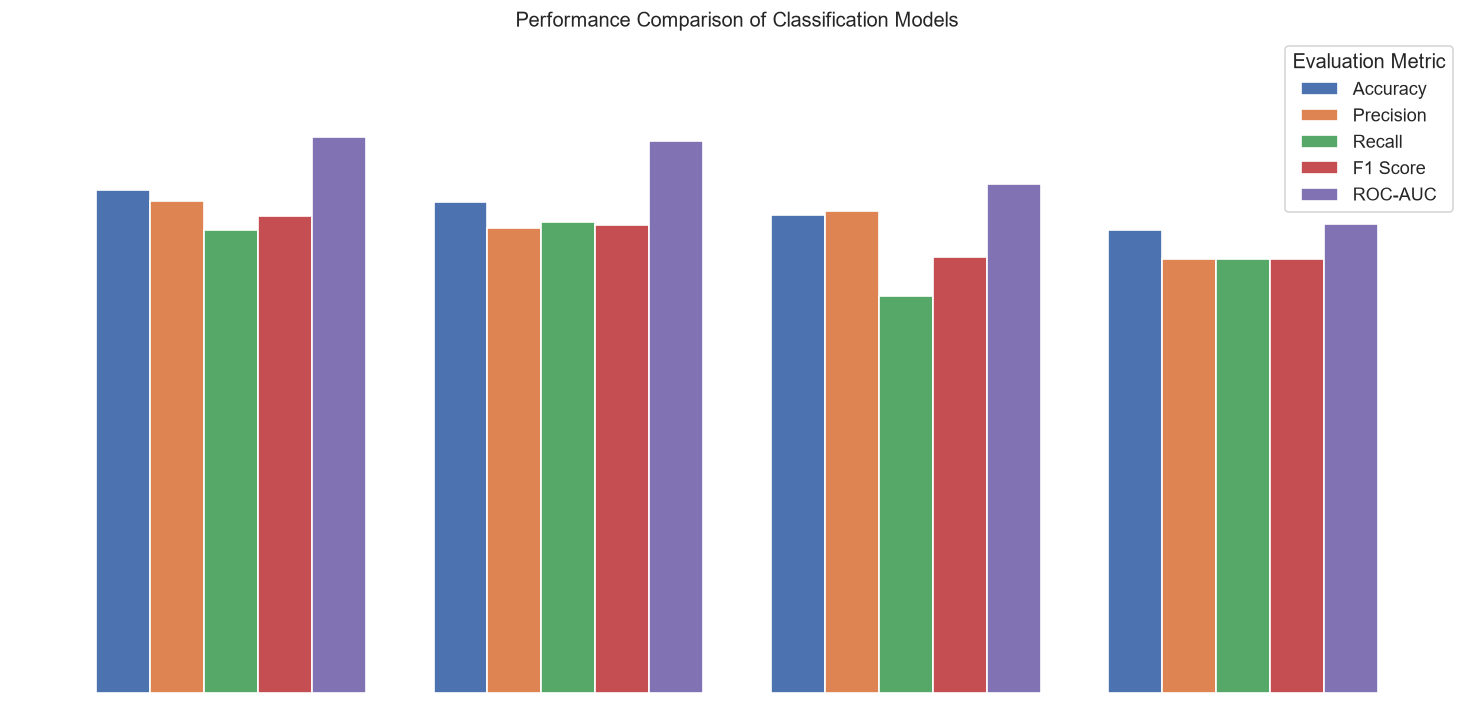

In [29]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

comparison_data = results_df.set_index("Model")[metrics_to_plot]

comparison_data.plot(
    kind="bar",
    figsize=(13, 7),
    ylim=(0, 1.05),
    width=0.8
)

plt.title("Performance Comparison of Classification Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(title="Evaluation Metric")
plt.tight_layout()
plt.axis(False)
plt.show()

In [30]:
for model_name, model in trained_models.items():
    print("=" * 70)
    print(model_name)
    print("=" * 70)
    print(classification_report(
        y_test,
        model_predictions[model_name],
        labels=["Not Suitable", "Suitable"],
        zero_division=0
    ))

Logistic Regression
              precision    recall  f1-score   support

Not Suitable       0.82      0.85      0.83       115
    Suitable       0.79      0.74      0.76        85

    accuracy                           0.81       200
   macro avg       0.80      0.80      0.80       200
weighted avg       0.80      0.81      0.80       200

Decision Tree
              precision    recall  f1-score   support

Not Suitable       0.77      0.77      0.77       115
    Suitable       0.69      0.69      0.69        85

    accuracy                           0.74       200
   macro avg       0.73      0.73      0.73       200
weighted avg       0.74      0.74      0.74       200

K-Nearest Neighbors
              precision    recall  f1-score   support

Not Suitable       0.76      0.86      0.81       115
    Suitable       0.77      0.64      0.70        85

    accuracy                           0.77       200
   macro avg       0.77      0.75      0.75       200
weighted avg       0

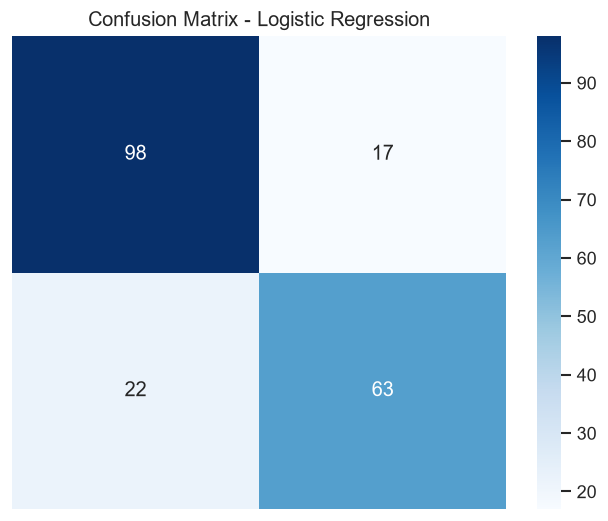

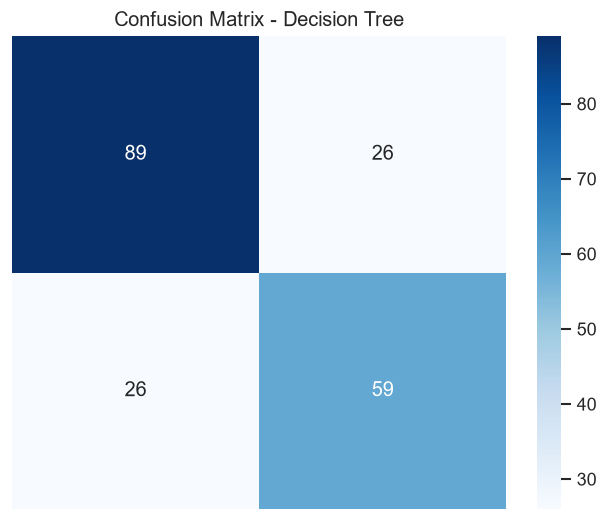

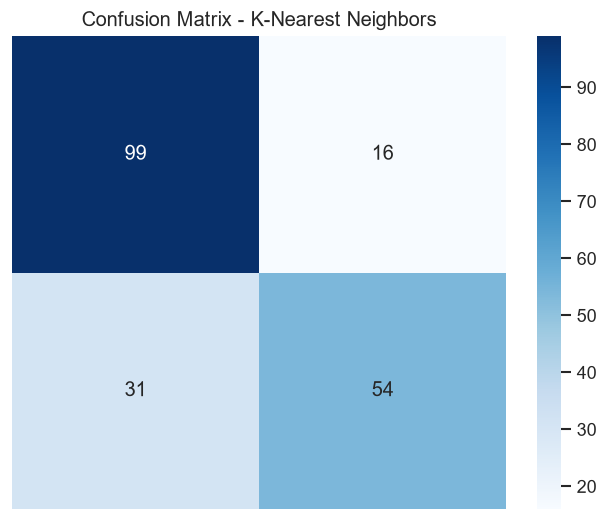

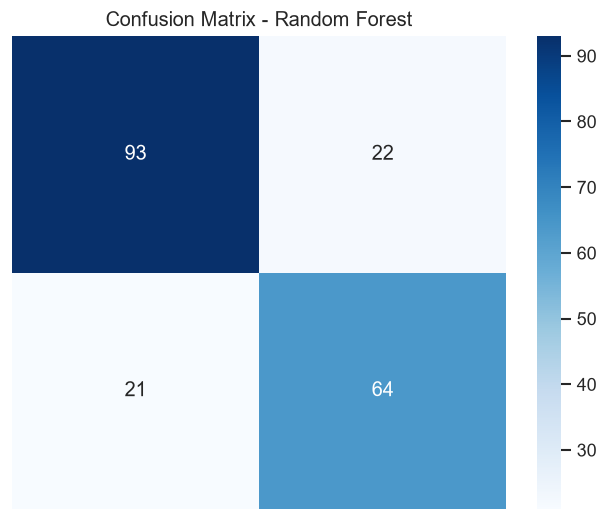

In [31]:
for model_name, y_pred in model_predictions.items():
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["Not Suitable", "Suitable"]
    )

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        linewidths=0,
        xticklabels=["Not Suitable", "Suitable"],
        yticklabels=["Not Suitable", "Suitable"]
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.axis(False)
    plt.show()

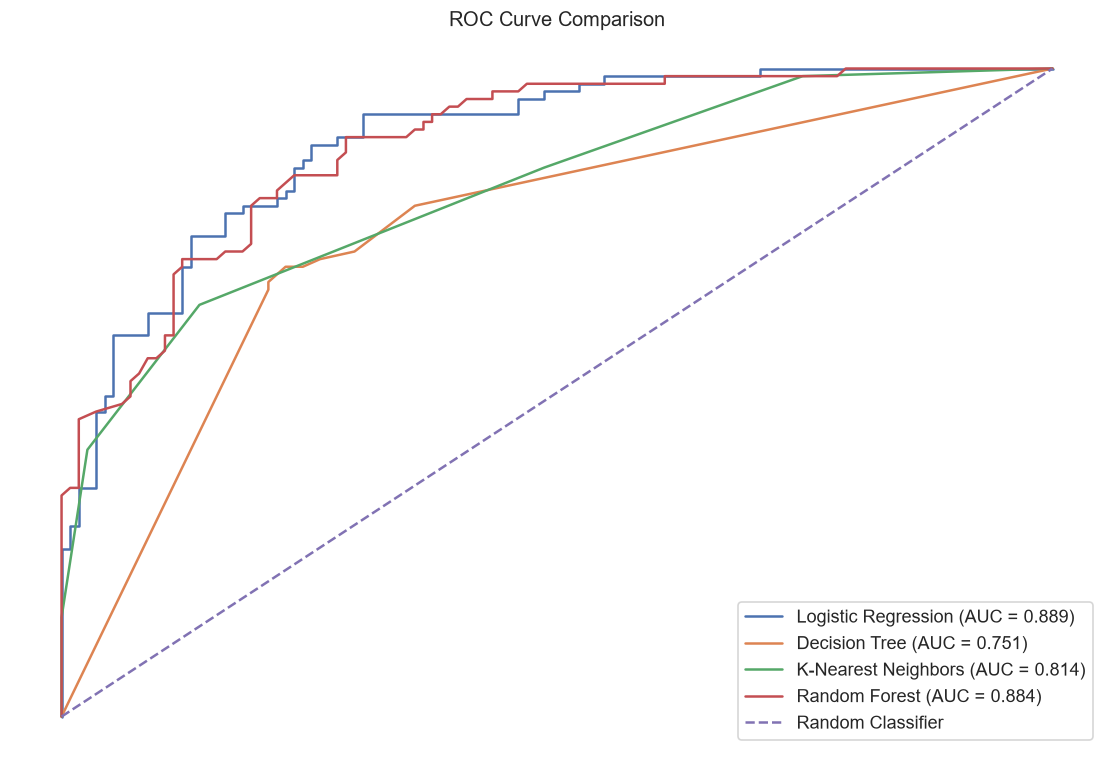

In [32]:
plt.figure(figsize=(10, 7))

for model_name, model in trained_models.items():
    suitable_index = list(model.classes_).index("Suitable")
    y_probability = model.predict_proba(X_test)[:, suitable_index]

    false_positive_rate, true_positive_rate, thresholds = roc_curve(
        (y_test == "Suitable").astype(int),
        y_probability
    )

    auc_value = roc_auc_score(
        (y_test == "Suitable").astype(int),
        y_probability
    )

    plt.plot(
        false_positive_rate,
        true_positive_rate,
        label=f"{model_name} (AUC = {auc_value:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.axis(False)
plt.show()

In [33]:
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

print("Selected model:", best_model_name)
display(results_df.iloc[[0]].round(4))

Selected model: Logistic Regression


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.805,0.7875,0.7412,0.7636,0.8891


In [34]:
best_predictions = best_model.predict(X_test)

print("Best Model:", best_model_name)
print("\nClassification Report:")
print(classification_report(
    y_test,
    best_predictions,
    labels=["Not Suitable", "Suitable"],
    zero_division=0
))

best_probability = best_model.predict_proba(X_test)[
    :, list(best_model.classes_).index("Suitable")
]

print("Accuracy:", round(accuracy_score(y_test, best_predictions), 4))
print("Precision:", round(precision_score(y_test, best_predictions, pos_label="Suitable", zero_division=0), 4))
print("Recall:", round(recall_score(y_test, best_predictions, pos_label="Suitable", zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, best_predictions, pos_label="Suitable", zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score((y_test == "Suitable").astype(int), best_probability), 4))

Best Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

Not Suitable       0.82      0.85      0.83       115
    Suitable       0.79      0.74      0.76        85

    accuracy                           0.81       200
   macro avg       0.80      0.80      0.80       200
weighted avg       0.80      0.81      0.80       200

Accuracy: 0.805
Precision: 0.7875
Recall: 0.7412
F1 Score: 0.7636
ROC-AUC: 0.8891


In [35]:
random_forest_pipeline = trained_models["Random Forest"]
fitted_preprocessor = random_forest_pipeline.named_steps["preprocessor"]
random_forest_classifier = random_forest_pipeline.named_steps["classifier"]

transformed_feature_names = fitted_preprocessor.get_feature_names_out()
feature_importance = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Importance": random_forest_classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance.head(15))

,Feature,Importance
0,numeric__Organic_Carbon_pct,0.201030
1,numeric__pH,0.100068
2,numeric__Available_N_kg_ha,0.074589
3,numeric__Available_S_mg_kg,0.054993
4,numeric__Available_P_kg_ha,0.054225
5,numeric__Available_K_kg_ha,0.042360
6,numeric__Available_Mn_mg_kg,0.033051
7,numeric__Soil_Moisture_pct,0.032374
8,numeric__EC_dS_m,0.032275
9,numeric__Available_Cu_mg_kg,0.032264


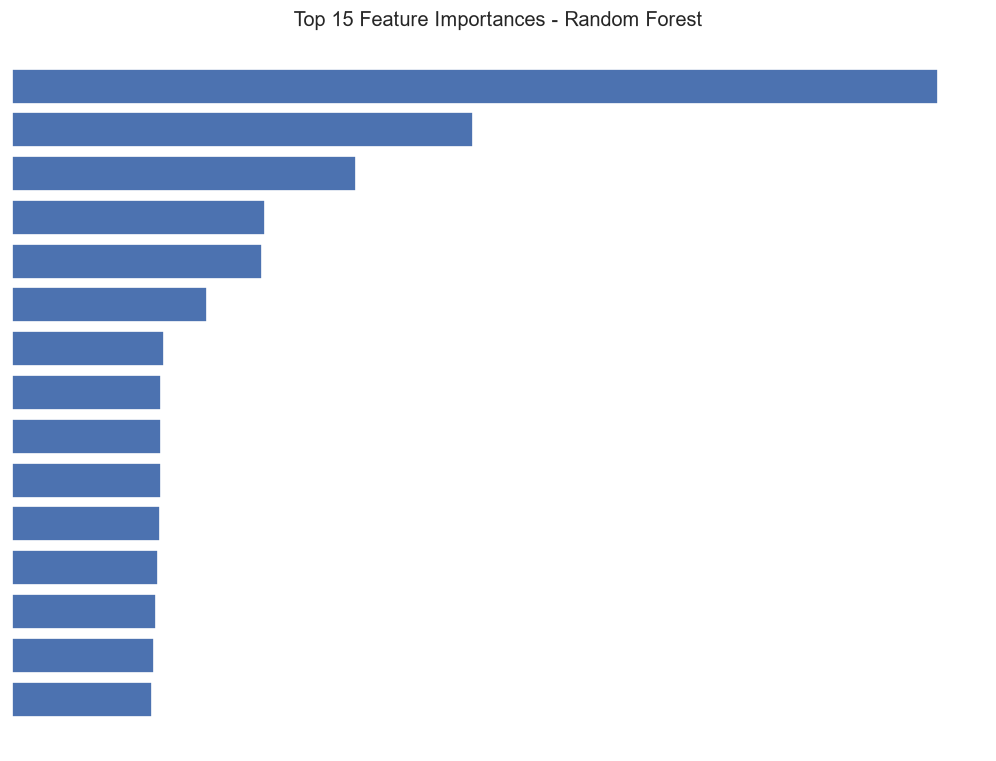

In [36]:
top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(11, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.axis(False)
plt.show()

In [37]:
permutation_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    scoring=make_scorer(f1_score, pos_label="Suitable")
)

permutation_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": permutation_result.importances_mean,
    "Importance_Std": permutation_result.importances_std
}).sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

display(permutation_importance_df)

,Feature,Importance_Mean,Importance_Std
0,Organic_Carbon_pct,0.197704,0.037617
1,pH,0.075588,0.031067
2,Available_P_kg_ha,0.067850,0.017903
3,Previous_Fertilizer_Usage,0.050756,0.020378
4,Available_N_kg_ha,0.044530,0.020223
5,Available_K_kg_ha,0.029582,0.011907
6,Previous_Pesticide_Usage,0.008026,0.018590
7,State,0.004594,0.009369
8,Crop,0.003358,0.012301
9,Soil_Moisture_pct,0.001508,0.003016


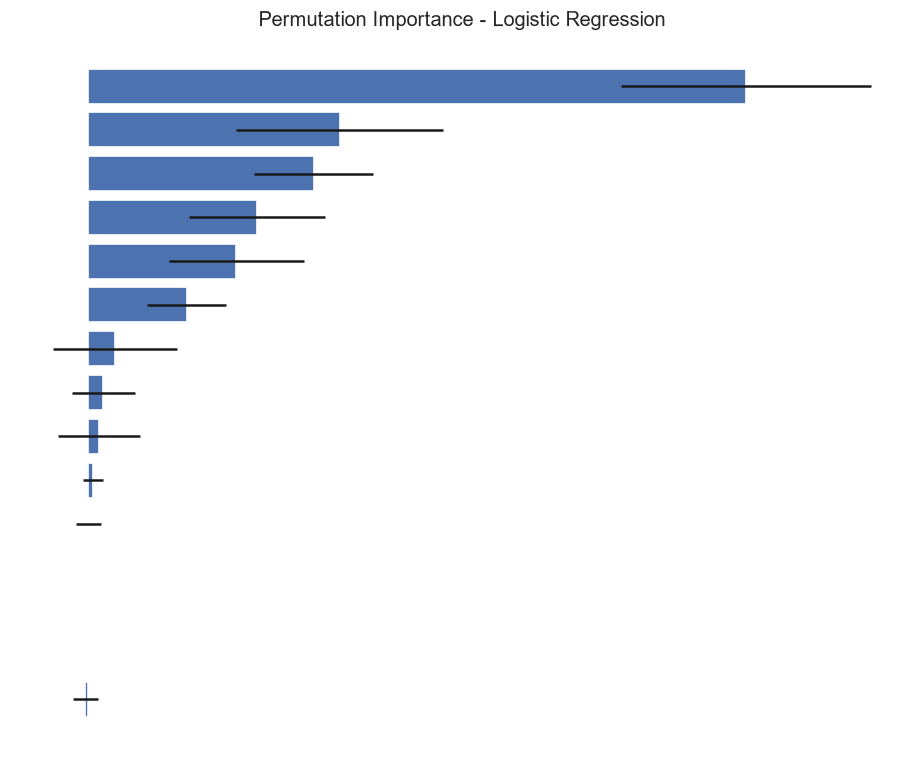

In [38]:
top_permutation_features = permutation_importance_df.head(15).sort_values(
    by="Importance_Mean",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_permutation_features["Feature"],
    top_permutation_features["Importance_Mean"],
    xerr=top_permutation_features["Importance_Std"]
)

plt.title(f"Permutation Importance - {best_model_name}")
plt.xlabel("Mean decrease in F1 score after shuffling")
plt.ylabel("Original Feature")
plt.tight_layout()
plt.axis(False)
plt.show()

In [39]:
model_artifact = {
    "model": best_model,
    "model_name": best_model_name,
    "feature_columns": X.columns.tolist(),
    "target_column": target_column,
    "positive_class": "Suitable",
    "excluded_columns": excluded_columns
}

model_file = "best_organic_farming_suitability_model.pkl"

joblib.dump(model_artifact, model_file)

print("Model saved as:", model_file)

Model saved as: best_organic_farming_suitability_model.pkl


In [40]:
saved_artifact = joblib.load("best_organic_farming_suitability_model.pkl")

loaded_model = saved_artifact["model"]
loaded_model_name = saved_artifact["model_name"]
feature_columns = saved_artifact["feature_columns"]

print("Loaded model:", loaded_model_name)
print("Number of required input features:", len(feature_columns))

Loaded model: Logistic Regression
Number of required input features: 21


In [41]:
new_soil_data = {
    "State": "West Bengal",
    "Soil_Type": "Loamy",
    "Crop": "Tomato",
    "pH": 6.5,
    "Organic_Carbon_pct": 0.8,
    "Available_N_kg_ha": 180.0,
    "Available_P_kg_ha": 25.0,
    "Available_K_kg_ha": 160.0,
    "Available_S_mg_kg": 15.0,
    "Available_Zn_mg_kg": 0.8,
    "Available_Fe_mg_kg": 5.0,
    "Available_Mn_mg_kg": 10.0,
    "Available_Cu_mg_kg": 0.6,
    "Available_B_mg_kg": 0.5,
    "EC_dS_m": 0.4,
    "Annual_Rainfall_mm": 1200.0,
    "Mean_Temperature_C": 25.0,
    "Soil_Moisture_pct": 30.0,
    "Previous_Fertilizer_Usage": "Organic",
    "Previous_Pesticide_Usage": "Low",
    "Years_Chemical_Input": 0
}

new_soil_df = pd.DataFrame([new_soil_data])
new_soil_df = new_soil_df[feature_columns]

display(new_soil_df)

,State,Soil_Type,Crop,pH,Organic_Carbon_pct,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Available_S_mg_kg,Available_Zn_mg_kg,...,Available_Mn_mg_kg,Available_Cu_mg_kg,Available_B_mg_kg,EC_dS_m,Annual_Rainfall_mm,Mean_Temperature_C,Soil_Moisture_pct,Previous_Fertilizer_Usage,Previous_Pesticide_Usage,Years_Chemical_Input
0,West Bengal,Loamy,Tomato,6.5,0.8,180.0,25.0,160.0,15.0,0.8,...,10.0,0.6,0.5,0.4,1200.0,25.0,30.0,Organic,Low,0


In [42]:
new_prediction = loaded_model.predict(new_soil_df)[0]

class_probabilities = loaded_model.predict_proba(new_soil_df)[0]
class_labels = loaded_model.classes_

suitable_probability = class_probabilities[
    list(class_labels).index("Suitable")
]

print("Selected Model:", loaded_model_name)
print("Predicted Organic Farming Suitability:", new_prediction)
print("Estimated probability of Suitable:", f"{suitable_probability:.2%}")

Selected Model: Logistic Regression
Predicted Organic Farming Suitability: Not Suitable
Estimated probability of Suitable: 14.02%
